# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Федів Андрій'      # прізвище та ім'я
GROUP        = 'СШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 13      # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Федів Андрій | СШІ-34 | номер 13


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 13   ·   Федів Андрій   ·   СШІ-34

   Ринок:  Zhytomyr
   Товар:  сир кисломолочний   (у наборі даних: Curd - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 28.10 |
| **Підпис** | α |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import pandas as pd

data = pd.read_csv("./ціни_україна_2014_2017.csv")
data = data[(data["ринок"] == MARKET) & (data["товар"] == GOOD)]

data.head(10)

,ринок,товар,одиниця,валюта,рік,місяць,ціна
9194,Zhytomyr,Curd - Retail,KG,UAH,2014,3,43.0500
9195,Zhytomyr,Curd - Retail,KG,UAH,2014,4,43.1033
9196,Zhytomyr,Curd - Retail,KG,UAH,2014,5,43.1300
9197,Zhytomyr,Curd - Retail,KG,UAH,2014,6,43.1300
9198,Zhytomyr,Curd - Retail,KG,UAH,2014,7,43.1300
9199,Zhytomyr,Curd - Retail,KG,UAH,2014,8,44.3400
9200,Zhytomyr,Curd - Retail,KG,UAH,2014,9,44.1367
9201,Zhytomyr,Curd - Retail,KG,UAH,2014,10,44.4167
9202,Zhytomyr,Curd - Retail,KG,UAH,2014,11,45.1167
9203,Zhytomyr,Curd - Retail,KG,UAH,2014,12,45.6100


In [4]:
print(data.isna().sum(axis=0))
print(data.nunique())

ринок      0
товар      0
одиниця    0
валюта     0
рік        0
місяць     0
ціна       0
dtype: int64
ринок       1
товар       1
одиниця     1
валюта      1
рік         4
місяць     12
ціна       39
dtype: int64


In [5]:
data["date"] = pd.to_datetime(dict(year=data["рік"], month=data["місяць"], day=1))

dated = data.set_index("date")["ціна"]  # .sort_index()

full_index = pd.date_range("2014-03-01", "2017-12-01", freq="MS")

dated = dated.reindex(full_index)

print(dated.head(5), dated.shape)
print("included months ", data.shape[0])
print("missed month ", dated[dated.isna()])

2014-03-01    43.0500
2014-04-01    43.1033
2014-05-01    43.1300
2014-06-01    43.1300
2014-07-01    43.1300
Freq: MS, Name: ціна, dtype: float64 (46,)
included months  45
missed month  2017-08-01   NaN
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 1:**

 Сітка 03.2014–12.2017 має 46 місяців, з них 45 мають вимір. Пропущено серпень 2017. У файлі немає рядка за цей місяць, тому пропуск видно лише після reindex на повну сітку. Серпня 2017 бракує одночасно в усіх рядах набору, отже, це прогалина на рівні джерела даних

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [6]:
mask = dated.isna()
dm1 = dated.ffill() # prev 
print(dm1[mask])
dm2 = dated.interpolate() 
print(dm2[mask])
dm3 = dated.bfill() # next
print(dm3[mask])

series = dm2  # далі працюємо з лінійною інтерполяцією

2017-08-01    71.4233
Freq: MS, Name: ціна, dtype: float64
2017-08-01    72.47665
Freq: MS, Name: ціна, dtype: float64
2017-08-01    73.53
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 2:**

Серпень 2017: `ffill` — 71.42, лінійна інтерполяція — 72.48, `bfill` — 73.53. Обрав лінійну: пропуск один, сусіди з обох боків відомі, ціна росте, тому `ffill` занижує, а `bfill` завищує.

Заповнювати неприпустимо, коли пропусків багато підряд і їх не вивести із сусідів. Приклад — Крим: після 03.2014 даних немає, заповнення було б вгадуванням.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

/tmp/ipykernel_440957/3221150263.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


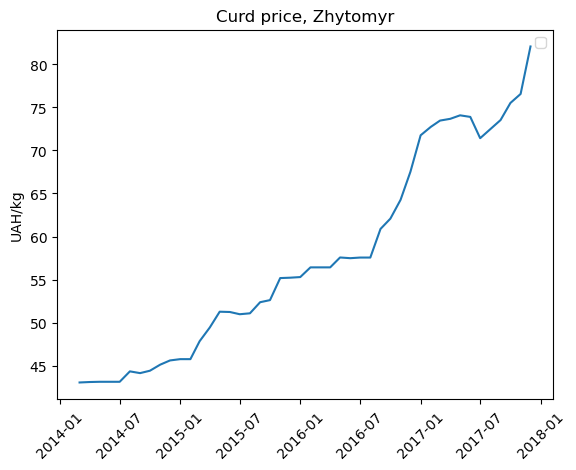

In [7]:
import matplotlib.pyplot as plt

aug = pd.Timestamp("2017-08-01")

plt.plot(series.index, series.values)
# plt.scatter([aug], [series[aug]], label="filled month")
plt.title("Curd price, Zhytomyr")
plt.ylabel("UAH/kg")
plt.xticks(rotation=45)
plt.legend()
plt.show()

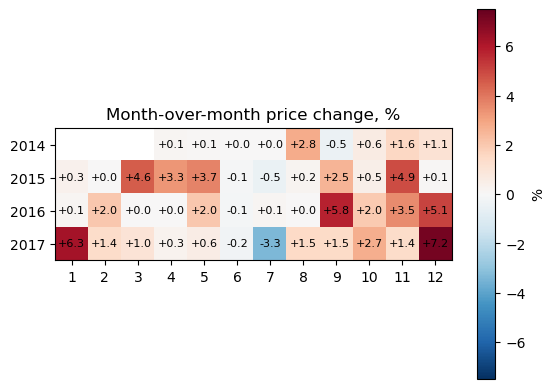

In [8]:
change = series.pct_change() * 100
table = change.to_frame("chg").pivot_table(index=change.index.year, columns=change.index.month, values="chg")

plt.imshow(table, cmap="RdBu_r", vmin=-7.5, vmax=7.5)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.values[i, j]
        if pd.notna(v):
            plt.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8)
plt.xticks(range(12), range(1, 13))
plt.yticks(range(len(table)), table.index)
plt.colorbar(label="%")
plt.title("Month-over-month price change, %")
plt.show()

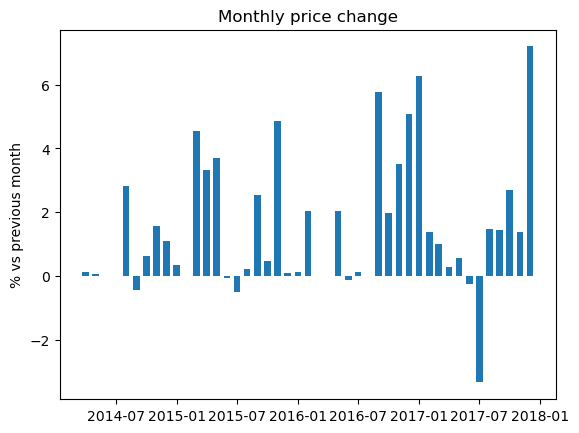

In [9]:
plt.bar(change.index, change.values, width=20)
plt.title("Monthly price change")
plt.ylabel("% vs previous month")
plt.show()

**Висновок до завдання 3:**

1. Лінія — як змінювалась ціна? Час неперервний, тому лінія. Вісь не від нуля, бо цікавить динаміка. Ціна росте з 43 до 82 грн.
2. Теплова карта рік × місяць — чи повторюються зміни в ті самі місяці? Сезон видно як стовпець одного кольору, білий = 0. Влітку ціна стоїть або падає, восени й узимку росте.
3. Стовпчики % зміни — коли були стрибки? Кожна зміна окрема, важливий знак, тому стовпчики від нуля.

Неочікувано: найбільші стрибки не у 2015 році, а в кінці 2016 – 2017 (+5.8 %, +6.3 %, +7.2 %); ціна падала лише 6 разів із 45.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

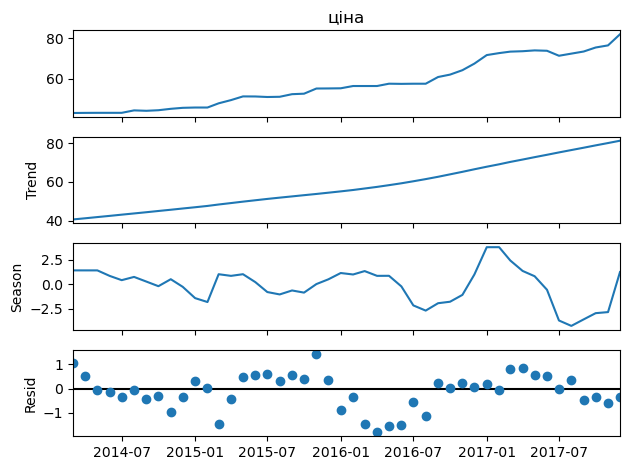

F_S = 0.861
F_T = 0.996
2016-01-01    1.14
2016-02-01    0.99
2016-03-01    1.34
2016-04-01    0.85
2016-05-01    0.86
2016-06-01   -0.22
2016-07-01   -2.16
2016-08-01   -2.69
2016-09-01   -1.94
2016-10-01   -1.78
2016-11-01   -1.09
2016-12-01    0.99
Freq: MS, Name: season, dtype: float64


In [10]:
from statsmodels.tsa.seasonal import STL

res = STL(series, period=12).fit()
res.plot()
plt.show()

T, S, R = res.trend, res.seasonal, res.resid
F_S = max(0, 1 - R.var() / (S + R).var())
F_T = max(0, 1 - R.var() / (T + R).var())
print("F_S =", round(F_S, 3))
print("F_T =", round(F_T, 3))
print(S["2016"].round(2))

**Висновок до завдання 4:**

F_S = 0.861, F_T = 0.996. F_S > 0.3, тож сезонність є: влітку ціна нижча за тренд (до −2.7 грн), узимку вища. Але тренд значно сильніший, а 46 місяців — це менше 4 циклів, тому сезон оцінено грубо (STL ще й частково записав у сезон стрибок кінця 2016 року).

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

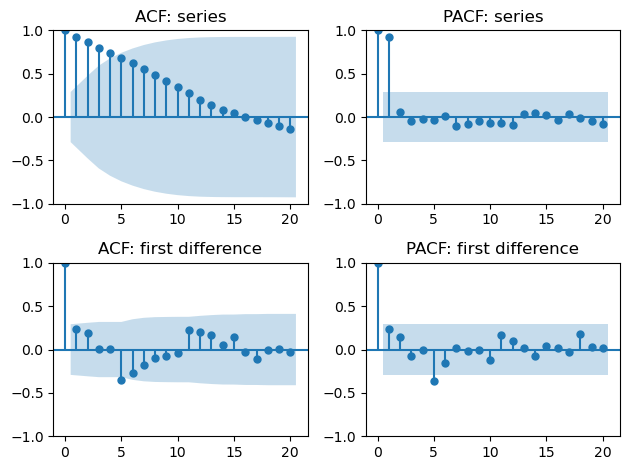

,ADF p,KPSS p
ряд,1.0000,0.01
перша різниця,0.0076,0.10


In [11]:
import warnings
warnings.filterwarnings("ignore")

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

diff = series.diff().dropna()

fig, ax = plt.subplots(2, 2)
plot_acf(series, lags=20, ax=ax[0, 0], title="ACF: series")
plot_pacf(series, lags=20, ax=ax[0, 1], title="PACF: series")
plot_acf(diff, lags=20, ax=ax[1, 0], title="ACF: first difference")
plot_pacf(diff, lags=20, ax=ax[1, 1], title="PACF: first difference")
plt.tight_layout()
plt.show()

tests = pd.DataFrame({
    "ADF p": [adfuller(series)[1], adfuller(diff)[1]],
    "KPSS p": [kpss(series)[1], kpss(diff)[1]],
}, index=["ряд", "перша різниця"])
tests.round(4)

**Висновок до завдання 5:**

Ряд нестаціонарний (ADF не відхиляє H₀, KPSS відхиляє), перша різниця стаціонарна. Тести узгоджуються, тобто d = 1. ACF ряду спадає повільно, як і буває при тренді; після різниці значущий лише лаг 5.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [12]:
import numpy as np

def naive(train, h):
    return np.repeat(train.iloc[-1], h)

def seasonal_naive(train, h):
    return train.values[-12:-12 + h]

def mean_forecast(train, h):
    return np.repeat(train.mean(), h)

def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

def metrics(true, pred):
    err = true - pred
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE": np.mean(np.abs(err / true)) * 100}

def rolling_origin(predict, x=series, folds=7, h=3):
    # фолд f: навчання на всьому до позиції -3f, перевірка на наступних 3 (як в Orange)
    scores = []
    for f in range(1, folds + 1):
        train = x.iloc[:-h * f]
        test = x.iloc[len(x) - h * f : len(x) - h * f + h]
        scores.append(metrics(test.values, predict(train, h)))
    return pd.DataFrame(scores).mean()

baselines = pd.DataFrame({
    "naive": rolling_origin(naive),
    "seasonal naive": rolling_origin(seasonal_naive),
    "mean": rolling_origin(mean_forecast),
    "drift": rolling_origin(drift),
}).T
print(baselines.round(3))

from sklearn.model_selection import train_test_split

idx = np.arange(len(series))
train_idx, test_idx = train_test_split(idx, test_size=0.25, random_state=67)
train_idx = np.sort(train_idx)

true, pred = [], []
for t in test_idx:
    before = train_idx[train_idx < t]
    if len(before) > 0:
        true.append(series.iloc[t])
        pred.append(series.iloc[before[-1]])

random_mae = metrics(np.array(true), np.array(pred))["MAE"]

print("naive MAE, folds:", round(baselines.loc["naive", "MAE"], 3))
print("naive MAE, random 75/25:", round(random_mae, 3))

                   MAE    RMSE    MAPE
naive            2.449   2.838   3.451
seasonal naive  12.080  12.114  17.321
mean            16.105  16.183  22.999
drift            2.147   2.388   3.015
naive MAE, folds: 2.449
naive MAE, random 75/25: 0.602


**Висновок до завдання 6:**

Найкращий базис — дрейф, бо ряд рівно росте, а дрейф продовжує цей нахил. Сезонний наївний і середнє беруть старі, набагато нижчі ціни.

Випадковий поділ 75/25 дає для наївного прогнозу MAE 0.60 замість 2.45, тобто приблизно в 4 рази краще


## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                MAE   RMSE   MAPE
ARIMA(1,1,1)  1.919  2.219  2.687
ARIMA(5,1,0)  1.848  2.213  2.600
drift         2.147  2.388  3.015


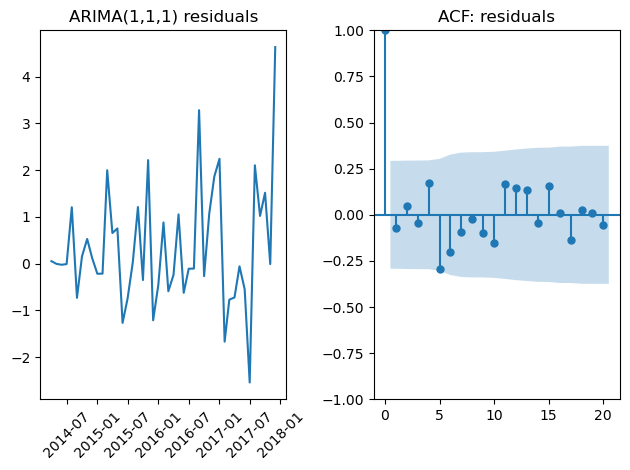

      lb_stat  lb_pvalue
6    8.764878   0.187239
12  14.246536   0.285243


In [13]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def arima111(train, h):  # обов'язковий порядок
    return ARIMA(train, order=(1, 1, 1)).fit().forecast(h).values

def arima510(train, h):  # власний вибір за PACF різниці
    return ARIMA(train, order=(5, 1, 0)).fit().forecast(h).values

compare = pd.DataFrame({
    "ARIMA(1,1,1)": rolling_origin(arima111),
    "ARIMA(5,1,0)": rolling_origin(arima510),
    "drift": baselines.loc["drift"],
}).T
print(compare.round(3))

model = ARIMA(series, order=(1, 1, 1)).fit()
resid = model.resid[1:]  # перший залишок — це саме перше значення ряду, відкидаємо

fig, ax = plt.subplots(1, 2)
ax[0].plot(resid)
ax[0].set_title("ARIMA(1,1,1) residuals")
ax[0].tick_params(axis="x", labelrotation=45)
plot_acf(resid, lags=20, ax=ax[1], title="ACF: residuals")
plt.tight_layout()
plt.show()

print(acorr_ljungbox(resid, lags=[6, 12]))

**Висновок до завдання 7:**

| | MAE | RMSE | MAPE, % |
|---|---|---|---|
| **ARIMA(1,1,1)** | **1.92** | **2.22** | **2.69** |
| ARIMA(5,1,0) — власний вибір | 1.85 | 2.21 | 2.60 |
| drift (найкращий базис) | 2.15 | 2.39 | 3.02 |

Сам обрав би ARIMA(5,1,0). d = 1 за тестами із завдання 5. У PACF першої різниці значущий лаг 5 (−0.42), а лаги 1–4 незначущі, тож p = 5. У ACF різниці теж виділяється лише лаг 5 (−0.35), а вищих MA-лагів немає, тож q = 0. Лаг 18 у PACF (0.31) вважаю випадковим. Лаг 5 поодинокий і змістового пояснення не має.

ARIMA(1,1,1) краща за найкращий базис дрейф (MAE 1.92 проти 2.15, ≈ 11 %), тож право на існування має, але виграш невеликий. Власна ARIMA(5,1,0) ще трохи краща (MAE 1.85).

Залишки ARIMA(1,1,1) без структури: ACF у межах смуги, Льюнг–Бокс p = 0.19 (лаг 6) і 0.29 (лаг 12) > 0.05.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

t              15.74
mean_before    51.69
mean_after     74.27
Name: 2017-01-01 00:00:00, dtype: float64
найменше |t| серед усіх дат: 9.1


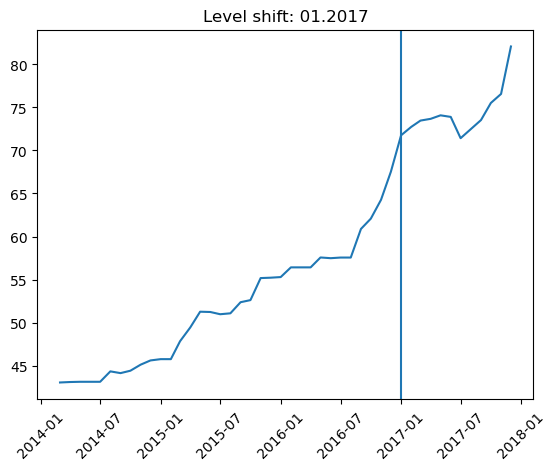

In [14]:
from scipy import stats

results = []
for k in range(6, len(series) - 5):  # щонайменше 6 місяців з боку
    before, after = series.iloc[:k], series.iloc[k:]
    t = stats.ttest_ind(after, before, equal_var=False).statistic
    results.append((series.index[k], t, before.mean(), after.mean()))

scan = pd.DataFrame(results, columns=["date", "t", "mean_before", "mean_after"]).set_index("date")
best = scan["t"].abs().idxmax()
print(scan.loc[best].round(2))
print("найменше |t| серед усіх дат:", round(scan["t"].abs().min(), 1))

plt.plot(series.index, series.values)
plt.axvline(best)
plt.title(f"Level shift: {best:%m.%Y}")
plt.xticks(rotation=45)
plt.show()

**Висновок до завдання 8:**
Значущість не доведено: t > 9 для будь-якої дати, бо в ряді з трендом після є завжди дорожчим. Але зсув реальний: з 09.2016 по 01.2017 ціна виросла на +- 25 % і далі пів року трималась на рівні 72–74 грн.

а також це не сезона зміна: в інші роки грудень–січень давали до 1%, тут 5.1% і 6.3%, і влітку ціна не повернулась.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [15]:
# Виправлення [3]: ряд колеги на повну сітку
prices = pd.read_csv("./ціни_україна_2014_2017.csv")
prices["date"] = pd.to_datetime(dict(year=prices["рік"], month=prices["місяць"], day=1))
buck = prices[(prices["ринок"] == "Vinnytsia") & (prices["товар"] == "Buckwheat grits - Retail")]
buck = buck.set_index("date")["ціна"].reindex(full_index)

print("пропусків після reindex:", buck.isna().sum(), buck[buck.isna()].index.strftime("%Y-%m").tolist())
buck = buck.interpolate()
print("після інтерполяції:", buck.isna().sum(), "| точок:", len(buck))

пропусків після reindex: 1 ['2017-08']
після інтерполяції: 0 | точок: 46


In [16]:
# Виправлення [13]: ADF + KPSS для ряду і першої різниці
buck_diff = buck.diff().dropna()
pd.DataFrame({
    "ADF p": [adfuller(buck)[1], adfuller(buck_diff)[1]],
    "KPSS p": [kpss(buck)[1], kpss(buck_diff)[1]],
}, index=["ряд", "перша різниця"]).round(4)

,ADF p,KPSS p
ряд,0.3482,0.0182
перша різниця,0.0399,0.0646


In [17]:
# Виправлення [17]: рухомий початок 7 × 3 і порівняння з базисами
def arima111_buck(train, h):
    return ARIMA(train, order=(1, 1, 1)).fit().forecast(h).values

pd.DataFrame({
    "ARIMA(1,1,1)": rolling_origin(arima111_buck, buck),
    "naive": rolling_origin(naive, buck),
    "drift": rolling_origin(drift, buck),
}).T.round(3)

,MAE,RMSE,MAPE
"ARIMA(1,1,1)",2.774,3.179,10.840
naive,2.551,2.893,10.107
drift,2.941,3.329,12.005


**Висновок до завдання 9:**

| клітинка | помилка | чим небезпечна |
|---|---|---|
| 3 | `isna()` без повної сітки, пропуск 08.2017 не помічено | нерівний крок ламає різниці, STL, ACF, ARIMA |
| 5 | подорожчання за двома крайніми точками | пропущено пік 36.9 грн у 2016 і падіння після нього |
| 7 | MAE порівнюється для товарів з різними цінами | у % гречка 6.4 % проти 1.9 %, тобто висновок протилежний |
| 9 | кореляція рівнів → «Львів визначає Вінницю» | спільний тренд завищує r; кореляція ≠ причинність |
| 11 | сезонність «доведено» самим STL | STL дає сезон завжди, треба рахувати F_S |
| 13 | ADF p = 0.233 — «стаціонарний», потім d = 2 | напрямок тесту переплутано, зайве диференціювання |
| 15 | аномалії на сирому ряді, поріг 1.3σ замість 2σ | «аномалії» — просто дешевий 2014 рік; шукати треба в залишках |
| 17 | випадковий `train_test_split`, `np.sort(y_te)` | модель бачить майбутнє, метрика безглузда |
| 19 | прогноз неперевіреною (2,2,1); «зростатиме» при 8.95 < 17.67 | висновок суперечить власному числу |
| 21 | стовпчики з обрізаною віссю Y | роздуває різницю |

Виправлення (код вище, на ряді колеги):
1. **[3]** — `reindex` на повну сітку: з'являється пропуск 2017-08, заповнюємо інтерполяцією, маємо 46 точок.
2. **[13]** — ряд: ADF p = 0.35, KPSS p = 0.02 — **нестаціонарний** (а не стаціонарний, як у колеги). Перша різниця: ADF p = 0.04, KPSS p = 0.06 — стаціонарна. Тести згодні, d = 1, друга різниця не потрібна.
3. **[17]** — на рухомому початку ARIMA(1,1,1) має MAE 2.77 (MAPE 10.8 %) і **програє наївному прогнозу** (2.55). Тобто «висока точність» не підтверджується: модель гірша за «завтра = як сьогодні».

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [18]:
export = pd.DataFrame({"date": series.index.strftime("%Y-%m-%d"), "price": series.values})
export.to_csv("ряд_для_orange.csv", index=False, encoding="utf-8")

check = pd.read_csv("ряд_для_orange.csv")
print("рядків даних:", len(check))
print("порожніх значень:", check.isna().sum().sum())
print(check[check["date"] == "2017-08-01"])
check.head()

рядків даних: 46
порожніх значень: 0
          date     price
41  2017-08-01  72.47665


,date,price
0,2014-03-01,43.0500
1,2014-04-01,43.1033
2,2014-05-01,43.1300
3,2014-06-01,43.1300
4,2014-07-01,43.1300


**Висновок до завдання 10:**

У файлі 46 рядків даних, порожніх значень немає, дата у форматі `РРРР-ММ-ДД`, серпень 2017 = 72.48.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [19]:
# Orange отримує той самий ряд, що й Python
orange_in = pd.read_csv("ряд_для_orange.csv", parse_dates=["date"]).set_index("date")["price"]
print("рядків:", len(orange_in))
print("збігається з series:", np.allclose(orange_in.values, series.values))
print("серпень 2017:", orange_in["2017-08-01"])

рядків: 46
збігається з series: True
серпень 2017: 72.47665


**Висновок до завдання 11:**

![Потік Orange](orange_screens/11_flow_4_widgets.png)

![Line Chart](orange_screens/11_line_chart.png)

Interpolate (лінійна) нічого не змінює, бо серпень 2017 заповнено ще в Python 72.48. Line Chart збігається з лінійним графіком із завдання 3: ті самі 46 точок, Orange отримав ряд без змін (перевірка вище).

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [20]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Seasonal Adjustment в Orange робить класичне розкладання; порівнюємо сезонну складову з STL
classic = seasonal_decompose(series, period=12).seasonal
pd.DataFrame({"Orange": classic, "STL": S}).groupby(series.index.month).mean().round(2).T

,1,2,3,4,5,6,7,8,9,10,11,12
Orange,1.00,0.92,1.06,0.82,1.08,0.04,-1.17,-2.22,-0.76,-1.03,-0.07,0.34
STL,1.17,0.98,1.55,1.12,1.03,0.07,-1.56,-1.81,-1.47,-1.45,-0.85,0.62


**Висновок до завдання 12:**

![Потік після завдання 12](orange_screens/12_flow.png)

![Correlogram: Δprice](orange_screens/12_correlogram_diff.png)

![Seasonal Adjustment](orange_screens/12_seasonal_adjustment.png)

Для першої різниці висновки збігаються з завданням 5: поза смугою лише лаг 5. Для самого ряду Orange показує тільки локальні піки |ACF|, тому видно один стовпчик (лаг 33), а не повільне спадання лагів 1–10, як у завданні 5.

Сезонна складова в Orange має ту саму форму, що й STL: з липня по жовтень ціна нижча за тренд (у серпні −2.2 грн проти −1.8 у STL), узимку вища. Різниця в тому, що Orange дає однаковий сезон для кожного року, а STL дозволяє йому змінюватися.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [21]:
n = len(series)
print("20 фолдів:", 20 * 3 + 1, ">", n)  # Orange вимагає folds·steps + max(p, d, q) ≤ n

for f in range(1, 8):
    print(f"фолд {f}: навчання до {series.index[n - 3 * f - 1]:%Y-%m}, "
          f"перевірка {series.index[n - 3 * f]:%Y-%m} … {series.index[n - 3 * f + 2]:%Y-%m}")

20 фолдів: 61 > 46
фолд 1: навчання до 2017-09, перевірка 2017-10 … 2017-12
фолд 2: навчання до 2017-06, перевірка 2017-07 … 2017-09
фолд 3: навчання до 2017-03, перевірка 2017-04 … 2017-06
фолд 4: навчання до 2016-12, перевірка 2017-01 … 2017-03
фолд 5: навчання до 2016-09, перевірка 2016-10 … 2016-12
фолд 6: навчання до 2016-06, перевірка 2016-07 … 2016-09
фолд 7: навчання до 2016-03, перевірка 2016-04 … 2016-06


**Висновок до завдання 13:**

![Повний потік](orange_screens/13_flow.png)

![Model Evaluation: 20 фолдів](orange_screens/13_eval_20_folds.png)

![Model Evaluation: 7 фолдів](orange_screens/13_eval_7_folds.png)

ARIMA(1,1,1), 7 фолдів × 3 кроки: RMSE 2.567, MAE 1.611, MAPE 0.028, POCID 85.0.

З типовими 20 фолдами Orange пише *«Supplied time series is too short for this many folds / step size»*. Orange вимагає, щоб folds · steps + max(p, d, q) ≤ довжина ряду, а тут 20 · 3 + 1 = 61 > 46.

Фолд f навчається на всьому до позиції −3f і перевіряє наступні 3 місяці. Фолд 1 навчається до 09.2017 і перевіряє 10–12.2017, фолд 7 навчається до 03.2016 і перевіряє 04–06.2016. Разом це останній 21 місяць ряду.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [22]:
# ті самі 7 фолдів, що в Orange; похибки всіх фолдів — в один масив
true, pred = [], []
for f in range(1, 8):
    true += list(series.iloc[len(series) - 3 * f : len(series) - 3 * f + 3])
    pred += list(arima111(series.iloc[:-3 * f], 3))
true, pred = np.array(true), np.array(pred)
err = true - pred

part1 = compare.loc["ARIMA(1,1,1)"]  # завдання 7: звичайні формули, середнє по фолдах

pd.DataFrame({
    "Orange": [2.567, 1.611, 0.028, 85.0],
    "Частина 1": [part1["RMSE"], part1["MAE"], part1["MAPE"], np.nan],
    "відтворення Orange": [np.sqrt(np.mean(err ** 2)),
                           np.median(np.abs(err)),
                           np.mean(np.abs(err)) / np.mean(np.abs(true)),
                           100 * np.mean(np.diff(true) * np.diff(pred) > 0)],
}, index=["RMSE", "MAE", "MAPE", "POCID"]).round(3)

,Orange,Частина 1,відтворення Orange
RMSE,2.567,2.219,2.567
MAE,1.611,1.919,1.611
MAPE,0.028,2.687,0.028
POCID,85.000,NaN,85.000


**Висновок до завдання 14:**

| Метрика | Orange | Частина 1 | відтворення в Python | Формула Orange |
|---|---|---|---|---|
| RMSE | 2.567 | 2.219 | 2.567 | √mean(e²) по всіх 21 похибках |
| MAE | 1.611 | 1.919 | 1.611 | median\|e\| |
| MAPE | 0.028 | 2.687 % | 0.028 | mean\|e\| / mean\|y\| (частка) |
| POCID | 85.0 | — | 85.0 | % пар, де Δy і Δŷ одного знака |

Прогнози в обох середовищах однакові (Orange використовує той самий statsmodels ARIMA), тож різниця лише в означеннях метрик. Усі чотири числа Orange відтворено до третього знака.

Назві не відповідає **MAE**: Orange рахує медіану |e| (1.611), а не середнє (1.919). **MAPE** теж інша: Orange ділить середню похибку на середнє y і дає частку (0.028 ≈ 2.8 %), а звичайна MAPE — це середнє |e/y|·100 % = 2.69 %.

За формулою збігається лише **RMSE**, але й вона відрізняється від Частини 1 (2.219 проти 2.567) через агрегацію: Orange рахує RMSE по всіх 21 похибці разом, а в Частині 1 RMSE усереднено по фолдах. Якщо зібрати похибки разом, виходить рівно 2.567. Для MAE і MAPE спосіб агрегації неважливий (фолди однакової довжини), а для RMSE важливий, бо корінь із середнього не дорівнює середньому з коренів.

Перш ніж порівнювати числа з двох інструментів, треба перевірити, що дані й фолди однакові, які формули стоять за назвами метрик і як результати фолдів зводяться в одне число.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [23]:
fact = np.where(np.diff(true) > 0, "зросла", "не зросла")
model = np.where(np.diff(pred) > 0, "зросла", "не зросла")

display(pd.crosstab(pd.Series(fact, name="насправді"), pd.Series(model, name="прогноз")))
print("частка правильних:", round(100 * np.mean(fact == model), 1), "%")

прогноз,зросла,не зросла
насправді,,
зросла,12,0
не зросла,3,5


частка правильних: 85.0 %


**Висновок до завдання 15:**

| | прогноз: зросла | прогноз: не зросла |
|---|---|---|
| **насправді зросла** | 12 | 0 |
| **насправді не зросла** | 3 | 5 |

Правильних (12 + 5) / 20 = 85 %, і це збігається з POCID в Orange.

Для рішення «купувати зараз чи чекати» модель корисна мало. Вона майже завжди прогнозує зростання, тож радить купувати, а всі 3 випадки, коли ціна насправді не зросла, пропустила. Це інше питання, ніж у MAE та RMSE: ті кажуть, на скільки гривень помиляється прогноз, а матриця — чи вгадано напрямок зміни.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Сезонність у ряді є, але слабка: за STL сила сезонності F_S = 0.86 (класичне розкладання дає 0.38), обидва значення вищі за поріг 0.3. Влітку сир дешевший за тренд приблизно на 2 грн, узимку дорожчий, і Seasonal Adjustment в Orange показав ту саму форму сезону. Головне в ряді — тренд (F_T = 0.996): за 46 місяців ціна зросла з 43 до 82 грн.

Найкращим методом стала власна ARIMA(5,1,0) з MAE 1.85, обов'язкова ARIMA(1,1,1) дала 1.92. Обидві перевершили найкращий базис, дрейф (2.15), і наївний прогноз (2.45), але виграш невеликий, близько 11–14 %.

Точку зміни рівня знайдено між 09.2016 і 01.2017: ціна виросла приблизно на 25 % і далі не повернулася, тож це не сезонний сплеск. Значущість t-тестом довести не вдалося, бо в ряді з трендом t велике для будь-якої дати. Можливе зовнішнє пояснення — подвоєння мінімальної зарплати з 01.2017, але в цих даних його не перевірити.

Однаково названі метрики в Orange і Python дали різні числа через різні формули: MAE в Orange — це медіана похибок, MAPE — частка середніх, а не відсотки, і всі похибки фолдів рахуються разом, а не усереднюються. За формулами Orange усі чотири числа відтворено в Python до третього знака.

Через лише 46 спостережень (менше 4 сезонних циклів) не вдалося надійно оцінити сезон і його стабільність. Також не вдалося довести, що ARIMA(5,1,0) справді краща за ARIMA(1,1,1): різниця 0.07 грн на 21 тестовому місяці. Невідомо й те, чи лаг 5 не випадковий.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Code (Anthropic, модель Claude Opus 5.5) |
| Для яких саме завдань | 2–10, 14–15; пояснення теорії (STL, ACF/PACF, ADF/KPSS, ARIMA, t-тест); налаштування Orange для 11–13 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код аналізу, чернетки висновків, пояснення методів, виправлення помилки в сітці дат (завдання 1) |
| Що ви змінили у згенерованому результаті й чому | спростив графіки (прибрав зайве оформлення); обрав теплову карту замість сезонного графіка, бо вона наочніша; змінив random_state; як власний порядок обрав ARIMA(5,1,0) через лаг 5 у PACF; скоротив висновки |
| Що з отриманого ви **перевірили самостійно** і яким способом | пропуск 08.2017 — переглядом даних; числа у висновках — з виводом клітинок; зошит — Restart & Run All; метрики Orange — відтворенням у Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | так: надто складне оформлення графіків; F_S за STL (0.86) завищений — класичне розкладання дає 0.38; після прибирання ARIMA(1,1,1) із завдання 7 зламалося завдання 14 |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: 28.10.2026